# Final Sports Betting Behavioral Profiling Analysis

Research question: Can simulated sports betting records reveal distinct behavioral profiles, and how does observed betting performance vary across those profiles?

This notebook runs the reproducible analysis script and displays its saved results. Open it from the repository root after installing `requirements.txt`. Phase 2 outputs remain separate. Final group IDs are ordered by mean stake (0 lower, 1 higher); these numeric labels reverse the Phase 2 labels without changing membership.


In [1]:
from pathlib import Path
import runpy
import pandas as pd
from IPython.display import display, Image, Markdown

root = Path.cwd()
if not (root / "final_analysis.py").exists():
    raise FileNotFoundError("Open this notebook from the Sports-Betting-Behavioral-Profiling repository root.")
runpy.run_path(str(root / "final_analysis.py"), run_name="__main__")
out = root / "outputs" / "final"


Validated data and created feature matrix
            method  k  silhouette    inertia  smallest_cluster  ari_to_kmeans_same_k
           K-Means  2      0.0829 92874.9979              1871                   NaN
           K-Means  3      0.0619 88193.7273              1524                   NaN
           K-Means  4      0.0688 84166.1125               296                   NaN
           K-Means  5      0.0640 80858.6005               294                   NaN
           K-Means  6      0.0728 77748.2042               292                   NaN
           K-Means  7      0.0672 75119.0444               291                   NaN
           K-Means  8      0.0625 73492.1913               290                   NaN
Ward agglomerative  2      0.1856        NaN               291                0.0019
Ward agglomerative  3      0.1052        NaN               291                0.0004
Ward agglomerative  4      0.0607        NaN               291                0.2676
Ward agglomerative  5  

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


## 1. Data validation and payout definitions
`gain` is gross payout; bettor net profit is `gain - stake`, which equals `-GGR`. All checks permit a 0.011 rounding tolerance for financial equalities.

In [2]:
import json
display(pd.Series(json.loads((out / "data_checks.json").read_text()), name="Value").to_frame())


,Value
rows,100000
bettors,5000
missing_cells,0
duplicate_rows,0
duplicate_bet_ids,0
invalid_stakes,0
invalid_odds,0
invalid_win_values,0
payout_mismatches,0
ggr_mismatches,0


## 2. Algorithms and stability
Both methods use the same 20-feature space. Silhouettes use the same sampled 2,000 bettors. Seed stability does not imply distinct groups. Ward finds a different, cycling-related split.

**method_comparison.csv**

,method,k,silhouette,inertia,smallest_cluster,ari_to_kmeans_same_k
0,K-Means,2,0.082879,92874.997882,1871,NaN
1,K-Means,3,0.061925,88193.727272,1524,NaN
2,K-Means,4,0.068762,84166.112516,296,NaN
3,K-Means,5,0.064030,80858.600534,294,NaN
4,K-Means,6,0.072808,77748.204193,292,NaN
5,K-Means,7,0.067240,75119.044446,291,NaN
6,K-Means,8,0.062550,73492.191327,290,NaN
7,Ward agglomerative,2,0.185553,NaN,291,0.001886
8,Ward agglomerative,3,0.105190,NaN,291,0.000442
9,Ward agglomerative,4,0.060650,NaN,291,0.267612


**seed_stability.csv**

,seed_a,seed_b,ARI
0,0,1,0.997591
1,0,2,0.998394
2,0,3,0.996789
3,0,42,0.996789
4,1,2,0.999197
5,1,3,0.999197
6,1,42,0.999197
7,2,3,0.998394
8,2,42,0.998394
9,3,42,1.000000


**method_cross_tab.csv**

,kmeans_cluster,0,1
0,0,114,1757
1,1,177,2952


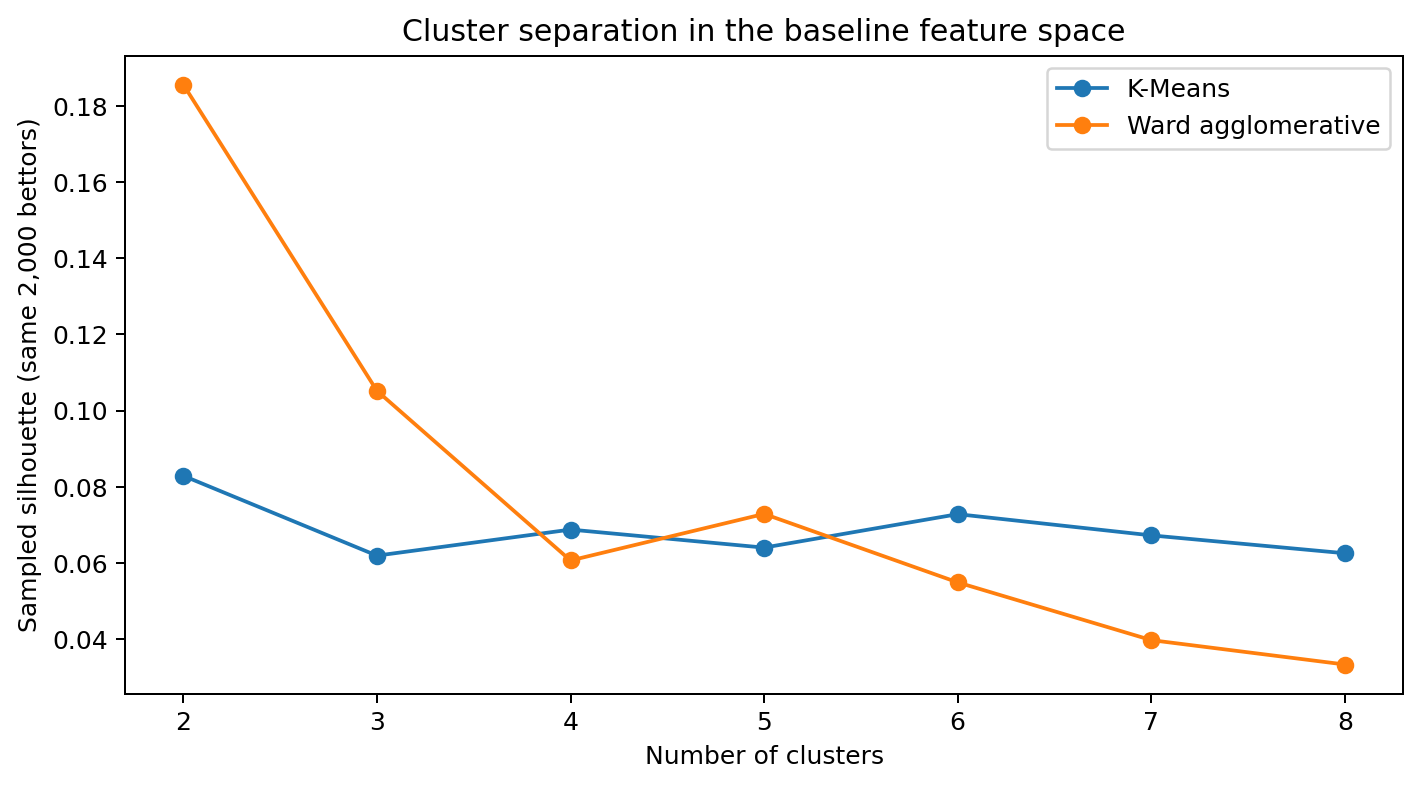

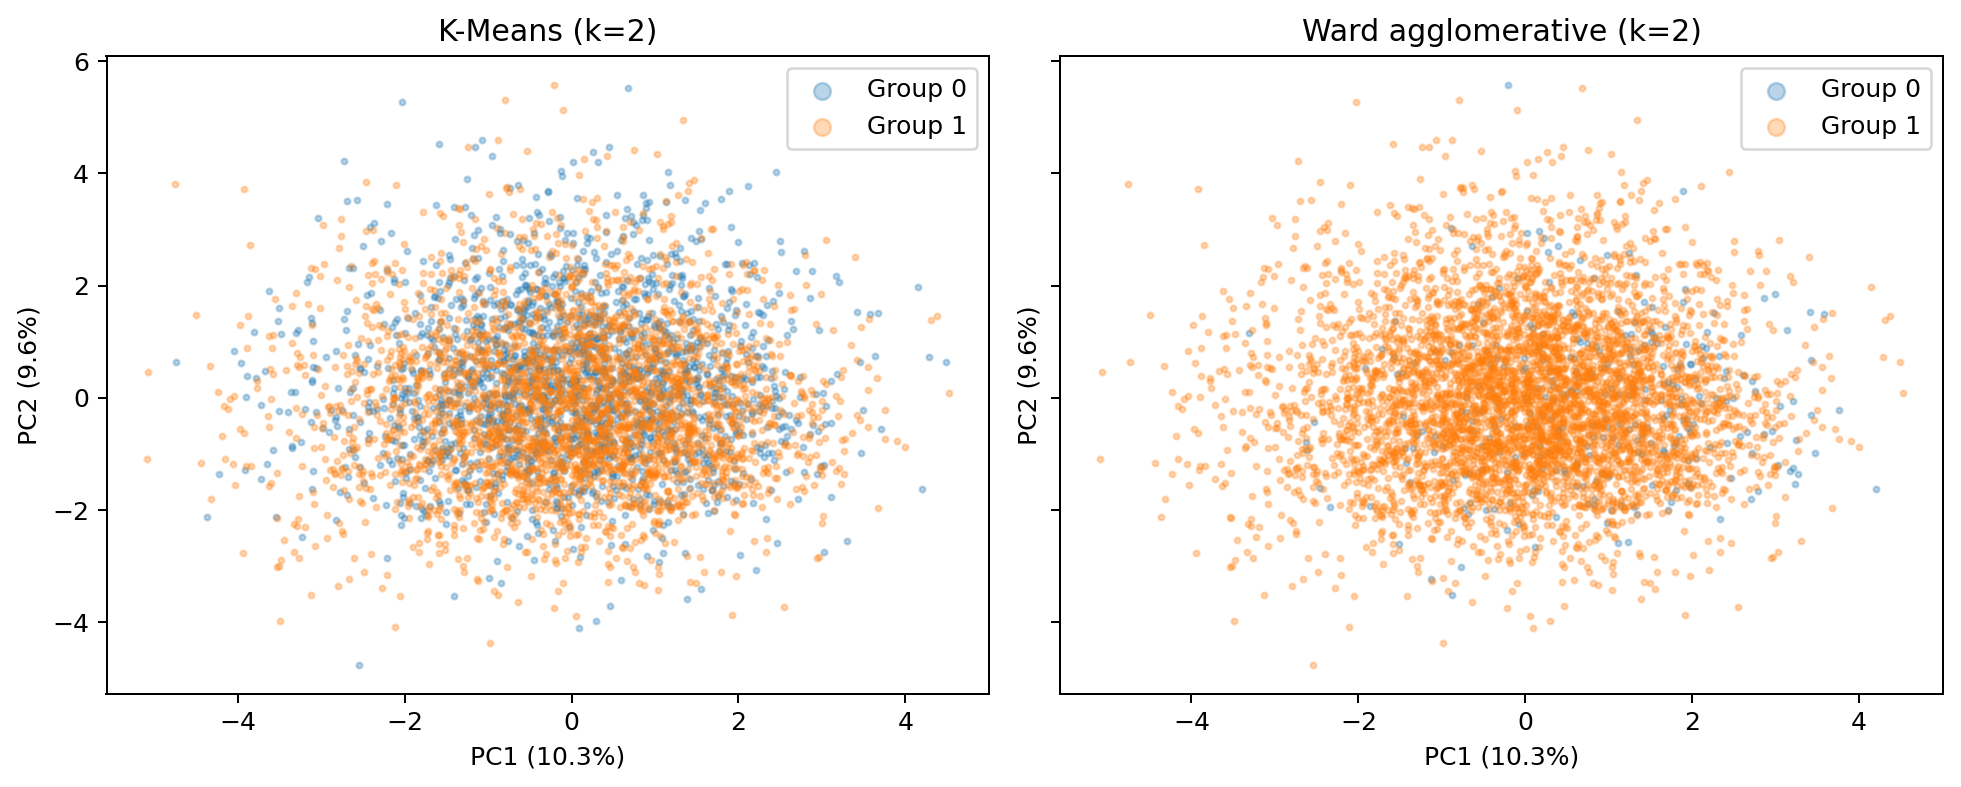

In [3]:
for name in ["method_comparison.csv", "seed_stability.csv", "method_cross_tab.csv"]:
    display(Markdown(f"**{name}**"))
    display(pd.read_csv(out / name))
for name in ["method_comparison.png", "method_pca.png"]:
    display(Image(filename=str(out / name), width=900))


## 3. Sensitivity and interpretation
ARI compares assignments with baseline K-Means. Silhouettes across different feature spaces should not be used as a common ranking. The baseline depends strongly on stake features and log transforms; rare standardized sport shares can drive alternative splits.

,variant,n_features,silhouette_own_space,ari_to_baseline,smallest_cluster
0,baseline_standard_log,20,0.082879,1.000000,1871
1,robust_log,20,0.088839,0.979228,1897
2,sport_block_downweighted,20,0.182926,0.984797,1884
3,no_stake_features,18,0.072677,0.000533,2334
4,standard_no_log,20,0.066442,0.006478,2320


,cluster,bettors,total_bets,average_stake,median_stake,stake_std,average_odds,odds_variance,sport_diversity,bet_type_diversity,sport_share_Badminton,sport_share_Baseball,sport_share_Basketball,sport_share_Cycling,sport_share_Football,sport_share_Formula 1,sport_share_Handball,sport_share_Ice Hockey,sport_share_Rugby,sport_share_Snooker,sport_share_Table Tennis,sport_share_Tennis,sport_share_Volleyball,bet_type_share_multiple,bet_type_share_single,stake_cv
0,0,1871,19.913950,23.148625,23.038870,11.771887,4.710644,20.077699,6.339925,1.999466,0.005572,0.030292,0.081900,0.003139,0.490826,0.006939,0.039811,0.053554,0.019092,0.030074,0.019652,0.180501,0.038648,0.352260,0.647740,0.521878
1,1,3129,20.051454,197.094405,197.362624,57.653905,4.693282,19.922049,6.351230,1.999041,0.004834,0.029693,0.080867,0.003061,0.493439,0.006714,0.039623,0.048416,0.019565,0.031233,0.019974,0.181673,0.040908,0.347946,0.652054,0.307915


,ward_cluster,bettors,total_bets,average_stake,median_stake,stake_std,average_odds,odds_variance,sport_diversity,bet_type_diversity,sport_share_Badminton,sport_share_Baseball,sport_share_Basketball,sport_share_Cycling,sport_share_Football,sport_share_Formula 1,sport_share_Handball,sport_share_Ice Hockey,sport_share_Rugby,sport_share_Snooker,sport_share_Table Tennis,sport_share_Tennis,sport_share_Volleyball,bet_type_share_multiple,bet_type_share_single,stake_cv
0,0,291,20.522337,120.592801,120.739777,37.722833,4.651373,19.680105,7.274914,2.000000,0.004694,0.027801,0.079487,0.052496,0.468223,0.006504,0.036275,0.048861,0.017841,0.029124,0.018476,0.169746,0.040472,0.334673,0.665327,0.397520
1,1,4709,19.967721,132.709060,132.834593,40.655537,4.702770,19.998844,6.289658,1.999151,0.005136,0.030048,0.081363,0.000037,0.493959,0.006817,0.039904,0.050430,0.019483,0.030903,0.019939,0.181945,0.040037,0.350480,0.649520,0.387391


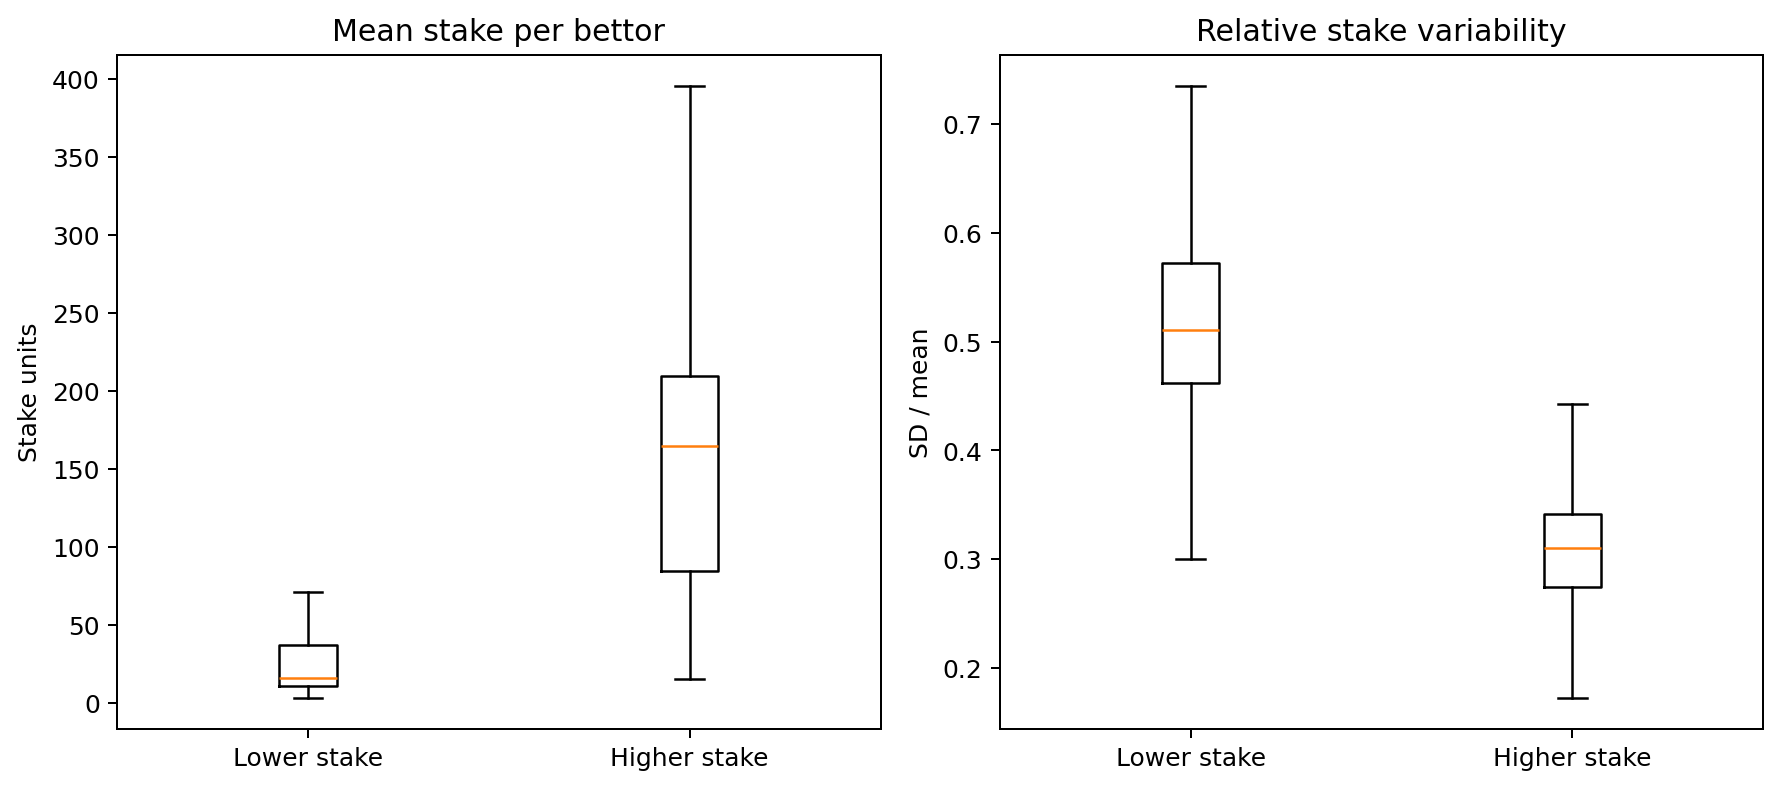

In [4]:
display(pd.read_csv(out / "feature_sensitivity.csv"))
display(pd.read_csv(out / "behavior_profiles.csv"))
display(pd.read_csv(out / "ward_behavior_profiles.csv"))
display(Image(filename=str(out / "stake_profiles.png"), width=900))


## 4. Observed performance
Mean bettor ROI weights each bettor equally; pooled ROI weights their stake exposure. Bootstrap intervals resample bettors within fixed groups and are exploratory. Rate fields are fractions (multiply by 100 for percentages). Currency is unspecified.

,cluster,bettors,bets,mean_win_rate,median_win_rate,mean_net_profit,median_net_profit,mean_profit_per_bet,mean_bettor_roi,median_bettor_roi,pooled_roi,profitable_bettor_share
0,0,1871,37259,0.365503,0.363636,-42.540502,-41.58,-2.146260,-0.096900,-0.177280,-0.091380,0.339925
1,1,3129,62741,0.363876,0.363636,-401.084283,-478.08,-19.976593,-0.104242,-0.194059,-0.101273,0.341962


,metric,mean_lower_stake,mean_higher_stake,difference_higher_minus_lower,ci95_low,ci95_high,bootstrap_replicates
0,win_rate,0.365503,0.363876,-0.001628,-0.007841,0.004691,3000
1,net_profit,-42.540502,-401.084283,-358.543780,-440.640289,-274.512858,3000
2,average_net_profit_per_bet,-2.146260,-19.976593,-17.830334,-22.047258,-13.554906,3000
3,roi,-0.096900,-0.104242,-0.007342,-0.035148,0.020581,3000


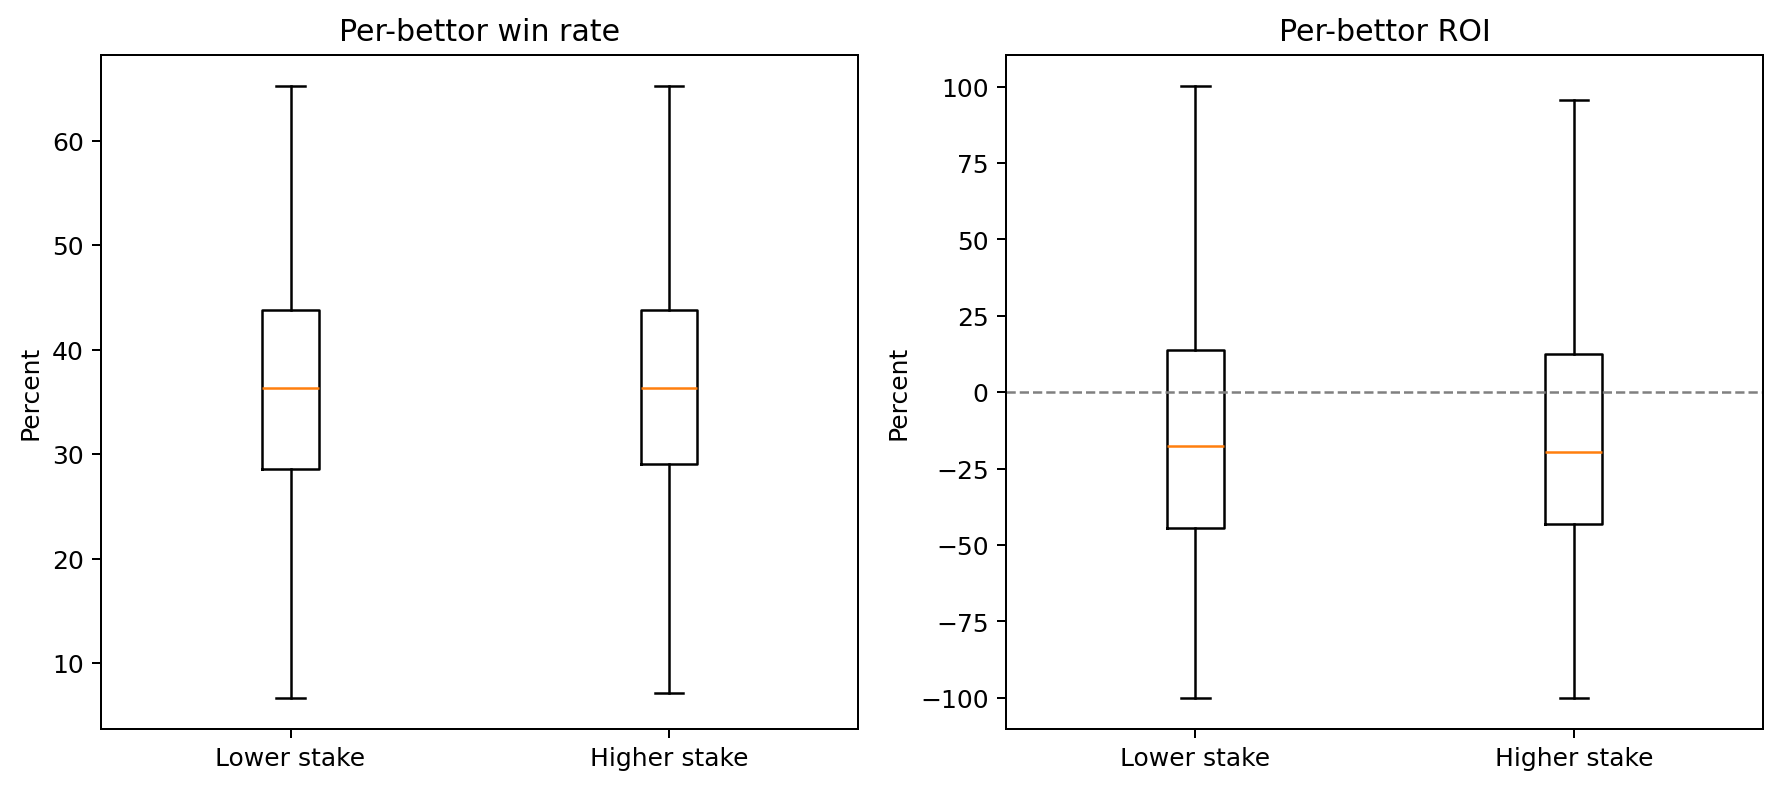

In [5]:
display(pd.read_csv(out / "cluster_performance.csv"))
display(pd.read_csv(out / "performance_contrasts.csv"))
display(Image(filename=str(out / "performance_distributions.png"), width=900))


## 5. Conclusion

Baseline K-Means produces weakly separated lower- and higher-stake profiles. Ward and alternative preprocessing can produce different assignments. Both baseline groups have negative average returns, similar win rates and ROI, and different monetary losses consistent with stake exposure. These are descriptive findings in simulated records, not evidence of real-world skill, motivation, causal effects, or future profitability.

The complete write-up is in `reports/final_report.md`. Submission and presentation preparation tasks are listed in `reports/presentation_and_demo_outline.md`.
